# Call panier **arithmétique** — proxy **Tensor-Train** : précision & speed-up vs Monte Carlo

Deux expériences, chacune exécutée **en deux passes strictement séparées : CRN d'abord, puis noCRN**.

**Budgets Monte Carlo**

| Budget | Rôle |
|---|---|
| `M_GT = 1 000 000` | **ground truth** — référence de toutes les erreurs (Exp A **et** Exp B) |
| `M_BUILD = 200 000` | prix MC aux **points d'entraînement** du proxy ; c'est aussi la méthode « MC budget-build » de l'Exp A |

**Proxy TT** : degré de Tchebychev **6** (7 points par dimension), rang max 7, sous-grille d'entraînement **adaptative** :
`{5: 300, 10: 1000, 15: 2000, 20: 3200, 25: 4500}` points.

---

### Expérience — erreurs & speed-up sur **10 000 points**
À `rho = 0.50`, `K = 100`, boucle `d ∈ {5,10,15,20,25}` par régime. Pour chaque `d` :
proxy TT (degré 6, sous-grille adaptative) évalué sur **10 000 points** uniformes de la boîte ;
**référence = MC 1M** (noCRN, seed indépendant, **partagée entre les deux régimes et mise en cache disque**).

*Sortie : 1 table par régime, index `d` :* `n_train`, **`tt_ranks`** (séquence de rangs du train de tenseurs),
**`t_train`** (évaluations MC aux points d'entraînement), **`t_fit`** (algo rang-adaptatif = « extensions »),
`t_build = t_train + t_fit`, `t_eval` (10 000 évaluations du proxy), `t_mc_1` (coût d'**un** prix MC 1M),
`spd_online = t_mc_1 / t_eval_1`, `spd_total = t_mc_1·N / (t_build + t_eval_1·N)` avec `N = N_SCEN_SPEED`,
et les erreurs `eabs/erel` (max & moyenne) vs la référence 1M.



## 0. Chargement de MoCaXExtend & imports

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter

from monitoring import chrono
from synthetic_market_factory import make_synthetic_market, make_basket
from moment_matching import moment_matching_prices
import cheb_experiment as ce

me = None
try:
    from mocax_extend_loader import load_mocax_extend
    me = load_mocax_extend(search_roots=[os.path.join(os.path.expanduser("~"), "mocax")])
    print("MoCaXExtend (TT) charge.")
except Exception as exc:
    print("MoCaXExtend (TT) INDISPONIBLE (%s) -> experience non executable." % type(exc).__name__)


MoCaXExtend (TT) charge.


## 1. Paramètres

In [ ]:
# ===================== PARAMETRES =====================
R = 0.01; T = 1.0; TAU = T
N_ASSETS = 25; SEED_MKT = 20240101
H_DOM = 1/252; CONF_DOM = 0.99            # boite vol-scaled (dimensionnement du domaine)

DIMS        = [5, 10, 15, 20, 25]
CORR_LEVELS = [0.20, 0.50, 0.80]          # Exp A
STRIKES     = [90.0, 100.0, 110.0]        # Exp A

# ------- budgets Monte Carlo -------
M_GT    = 1_000_000                       # ground truth (reference des erreurs, Exp A ET Exp B)
M_BUILD =   200_000                       # points d'entrainement du proxy + methode "MC budget-build"

# ------- proxy TT -------
TT_ORDER     = 6                          # degre 6 -> 7 points par dimension
SUBGRID_BY_D = {5: 300, 10: 1000, 15: 2000, 20: 3200, 25: 4500}   # sous-grille adaptative
TT_PARAMS    = dict(tolerance=1e-3, rel_tolerance=1e-8, max_iters=100,
                    max_rank=7, max_rounds=5, print_progress=False)

# ------- Exp B -------
N_TEST   = 10_000                     # points d'evaluation aleatoires
RHO_B        = 0.50; K_B = 100.0
N_SCEN_SPEED = 100_000                    # charge de reference pour spd_total

# ------- seeds (independants par role) -------
SEED      = 12345      # noeuds d'entrainement + MC budget-build
SEED_PT   = 777        # point unique s*(d) de l'Exp A
SEED_GT   = 98765      # ground truth 1M
SEED_REF  = 54321      # reference 1M de l'Exp B
SEED_TEST = 2468       # les 10 000 points de test

FAST = False           # True = smoke test rapide de toute la chaine
if FAST:
    M_GT = 100_000; M_BUILD = 50_000; N_TEST_B = 500
    SUBGRID_BY_D = {5: 100, 10: 200, 15: 300, 20: 400, 25: 500}
    print("*** MODE FAST : budgets reduits (test de chaine, resultats non exploitables). ***")

markets = {rho: make_synthetic_market(n=N_ASSETS, rho=rho, rate=R, seed=SEED_MKT)
           for rho in CORR_LEVELS + ([RHO_B] if RHO_B not in CORR_LEVELS else [])}
CACHE_DIR = "cache_expB"; os.makedirs(CACHE_DIR, exist_ok=True)


print("Exp B : rho=%.2f, K=%g, d in %s, %d points de test, ref MC %d (cache: %s/)" %
      (RHO_B, K_B, DIMS, N_TEST_B, M_GT, CACHE_DIR))
print("TT : degre %d (%d pts/dim), sous-grille %s, max_rank=%d" %
      (TT_ORDER, TT_ORDER+1, SUBGRID_BY_D, TT_PARAMS["max_rank"]))
if me is None: print("\n*** MoCaXExtend absent : les cellules d'experience s'arreteront proprement. ***")


Exp A : rho x d x K = 3 x 5 x 3 = 45 configs / regime
Exp B : rho=0.50, K=100, d in [5, 10, 15, 20, 25], 10000 points de test, ref MC 1000000 (cache: cache_expB/)
TT : degre 6 (7 pts/dim), sous-grille {5: 300, 10: 1000, 15: 2000, 20: 3200, 25: 4500}, max_rank=7


## 2. Outils : build TT **instrumenté** (`t_train` / `t_fit` / rangs) & helpers

`build_tt_instrumented` reprend `cheb_experiment.build_tt` à l'identique, mais **chronomètre séparément** :
- **`t_train`** — les évaluations Monte Carlo aux points de la sous-grille (la partie coûteuse) ;
- **`t_fit`** — `gen_train_val_data` + `run_rank_adaptive_algo` (les « extensions » rang-adaptatives) ;

et **extrait la séquence de rangs** finale du train de tenseurs (introspection tolérante aux versions de MoCaXExtend :
si aucun accesseur connu n'existe, la colonne liste les attributs candidats trouvés).
Aucune modification des `.py` existants n'est nécessaire.

In [ ]:
def final_ranks(obj):
    """Sequence de rangs du tenseur entraine ([1, r1, ..., 1]) ou None.

    Les rangs sont portes par obj.trained_tt_tensor (nom documente MoCaX),
    avec replis defensifs (methodes/attributs alternatifs, reconstruction
    depuis les formes de coeurs).
    """
    holders = (obj, getattr(obj, "trained_tt_tensor", None),
               getattr(obj, "cheb_tensor_tt", None))
    for h in holders:
        if h is None:
            continue
        for name in ("ranks", "get_ranks", "tt_ranks", "get_tt_ranks"):
            v = getattr(h, name, None)
            if v is None:
                continue
            if callable(v):
                try:
                    v = v()
                except Exception:
                    continue
            try:
                out = [int(x) for x in np.asarray(v).ravel()]
            except (TypeError, ValueError):
                continue
            if out:
                return out
        cores = getattr(h, "cores", None)
        if cores is not None:
            try:
                return [int(c.shape[0]) for c in cores] + [1]
            except Exception:
                pass
    return None


def build_tt_instrumented(pricer, domain, tt_order, me, subgrid, tt_params):
    """Comme ce.build_tt, avec chrono t_train / t_fit + rangs.

    Renvoie (obj, eval_many, times, ranks, n_train) ou times = {"t_train", "t_fit"}.
    """
    if me is None:
        raise RuntimeError("MoCaXExtend indisponible.")
    times = {}
    d = len(domain)
    ranges = [[float(a), float(b)] for a, b in domain]
    obj = me.MocaxExtend(d, [int(tt_order)] * d, ranges)
    n_train = min(int(subgrid), obj.get_tensor_size())
    pts = obj.subgrid_by_number(n_train)

    with chrono(times, "t_train"):                      # <- evaluations MC aux noeuds
        vals = np.asarray([pricer(pt) for pt in pts], dtype=float)

    try:
        obj.set_subgrid_values(vals)
    except (AttributeError, TypeError):
        obj.set_subgrid_values(vals.tolist())

    with chrono(times, "t_fit"):                        # <- "extensions" rang-adaptatives
        try:
            obj.gen_train_val_data(0.8)
        except TypeError:
            obj.gen_train_val_data()
        obj.run_rank_adaptive_algo(**tt_params)

    def _eval(q):
        arr = np.asarray(q, dtype=float)
        try:
            return np.asarray(obj.cheb_tensor_evals(arr))
        except (AttributeError, TypeError):
            return np.asarray(obj.cheb_tensor_evals(arr.tolist()))

    return obj, _eval, times, final_ranks(obj), n_train


def mc_price_once(deriv, mkt, point, M, regime, seed):
    """Un prix MC (M trajectoires) au point donne, dans le regime demande."""
    return ce.MCNodePricer(deriv, mkt, tau=TAU, M_paths=M, regime=regime, seed=seed)(np.asarray(point, float))


def price_many_progress(pricer, points, label="", every=500):
    """price_many avec affichage de progression + ETA (utile pour la ref 1M x 10k points)."""
    pts = np.asarray(points, float)
    out = np.empty(len(pts))
    t0 = perf_counter()
    for i, p in enumerate(pts):
        out[i] = pricer(p)
        if (i + 1) % every == 0 or (i + 1) == len(pts):
            el = perf_counter() - t0
            eta = el / (i + 1) * (len(pts) - i - 1)
            print("    %s : %6d / %d  (%.0fs ecoulees, ETA %.0fs)" % (label, i + 1, len(pts), el, eta))
    return out

## 3. Expérience -- 10 000 points : erreurs, temps, speed-ups, rangs TT

- **Référence** : MC **1M** noCRN (seed `SEED_REF`, indépendant du build) sur les 10 000 points —
  **calculée une seule fois par `d`**, partagée entre CRN et noCRN, **cachée sur disque** (`cache_expB/`).
- **`t_mc_1`** : coût d'**un** prix MC 1M, mesuré en **noCRN** (tirages frais à chaque appel = coût réaliste ;
  en CRN, les tirages sont faits une fois à l'init et le chrono par appel sous-estimerait le vrai coût MC).
- `t_build = t_train + t_fit` ; `spd_online = t_mc_1 / t_eval_1` ;
  `spd_total = t_mc_1·N / (t_build + t_eval_1·N)`, `N = N_SCEN_SPEED`.

In [8]:
_REFB_CACHE = {}
def expB_ref(d):
    """(deriv, box, test, p_ref) pour la dimension d -- ref 1M cachee memoire + disque."""
    if d in _REFB_CACHE:
        return _REFB_CACHE[d]
    mkt = markets[RHO_B]
    deriv = make_basket(d, mkt, K_B, T)
    box = ce.vol_scaled_box(mkt.spots[:d], mkt.vols[:d], H_DOM, CONF_DOM)
    test = ce.sample_box_uniform(box, N_TEST_B, seed=SEED_TEST)
    fn = os.path.join(CACHE_DIR, "ref_d%02d_rho%.2f_K%g_M%d_N%d_s%d.npy"
                      % (d, RHO_B, K_B, M_GT, N_TEST_B, SEED_REF))
    if os.path.exists(fn):
        p_ref = np.load(fn)
        print("  ref d=%2d chargee du cache (%s)" % (d, fn))
    else:
        print("  ref d=%2d : %d prix MC a %d trajectoires (long ; cache ensuite)..." % (d, N_TEST_B, M_GT))
        pricer = ce.MCNodePricer(deriv, mkt, tau=TAU, M_paths=M_GT, regime="noCRN", seed=SEED_REF)
        p_ref = price_many_progress(pricer, test, label="ref d=%d" % d, every=500)
        np.save(fn, p_ref)
    _REFB_CACHE[d] = (deriv, box, test, p_ref)
    return _REFB_CACHE[d]


def run_expB(regime):
    """Une passe complete de l'Exp B dans le regime donne -> DataFrame indexe d."""
    if me is None:
        print("MoCaXExtend indisponible : experience non executee."); return pd.DataFrame()
    mkt = markets[RHO_B]
    rows = []
    print("\n[Exp B | %s] rho = %.2f, K = %g" % (regime, RHO_B, K_B))
    for d in DIMS:
        deriv, box, test, p_ref = expB_ref(d)

        # --- cout d'UN prix MC 1M (noCRN = tirages frais -> chrono honnete) ---
        timer = ce.MCNodePricer(deriv, mkt, tau=TAU, M_paths=M_GT, regime="noCRN", seed=SEED)
        n_time = 5
        with chrono() as c_mc:
            for p in test[:n_time]:
                timer(p)
        t_mc_1 = c_mc.elapsed / n_time

        # --- build TT instrumente (regime courant) ---
        node = ce.MCNodePricer(deriv, mkt, tau=TAU, M_paths=M_BUILD, regime=regime, seed=SEED)
        try:
            _, ev, tms, ranks, n_tr = build_tt_instrumented(
                node, box, TT_ORDER, me, SUBGRID_BY_D[d], TT_PARAMS)
        except Exception as exc:
            print("  d=%2d | ECHEC build : %s" % (d, exc)); continue
        t_build = tms["t_train"] + tms["t_fit"]

        # --- evaluation du proxy sur les 10 000 points ---
        with chrono() as c_ev:
            p_surr = np.asarray(ev(test), float).ravel()
        t_eval = c_ev.elapsed
        t_eval_1 = t_eval / len(test)

        spd_online = t_mc_1 / max(t_eval_1, 1e-12)
        spd_total = (t_mc_1 * N_SCEN_SPEED) / max(t_build + t_eval_1 * N_SCEN_SPEED, 1e-12)
        e = ce.price_errors(p_surr, p_ref)

        rows.append(dict(regime=regime, d=d, n_train=n_tr, tt_ranks=str(ranks),
                         t_train=tms["t_train"], t_fit=tms["t_fit"], t_build=t_build,
                         t_eval=t_eval, t_mc_1=t_mc_1,
                         spd_online=spd_online, spd_total=spd_total,
                         eabs_max=e["eabs_max"], eabs_mean=e["eabs_mean"],
                         erel_max=e["erel_max"], erel_mean=e["erel_mean"]))
        print("  d=%2d | n_train=%4d | ranks=%s | t_train=%.0fs t_fit=%.1fs | t_eval=%.2fs | "
              "t_mc_1=%.2fs | spd_on=%.0f spd_tot=%.0f | erel max/moy = %.2e / %.2e"
              % (d, n_tr, ranks, tms["t_train"], tms["t_fit"], t_eval, t_mc_1,
                 spd_online, spd_total, e["erel_max"], e["erel_mean"]))
    return pd.DataFrame(rows).set_index("d")


def show_expB(df, regime):
    if not len(df):
        return
    cols = ["n_train", "tt_ranks", "t_train", "t_fit", "t_build", "t_eval", "t_mc_1",
            "spd_online", "spd_total", "eabs_max", "eabs_mean", "erel_max", "erel_mean"]
    fmt = {"t_train": "{:.1f}", "t_fit": "{:.2f}", "t_build": "{:.1f}", "t_eval": "{:.3f}",
           "t_mc_1": "{:.3f}", "spd_online": "{:,.0f}", "spd_total": "{:,.0f}",
           "eabs_max": "{:.3e}", "eabs_mean": "{:.3e}", "erel_max": "{:.3e}", "erel_mean": "{:.3e}"}
    display(df[cols].style.format(fmt).set_caption(
        "Exp B [%s] — rho=%.2f, K=%g — proxy TT vs MC 1M sur %d points" % (regime, RHO_B, K_B, N_TEST_B)))


### 3.1 Exp — **CRN**

In [9]:
dfB_CRN = run_expB("CRN")
show_expB(dfB_CRN, "CRN")



[Exp B | CRN] rho = 0.50, K = 100
  ref d= 5 : 10000 prix MC a 1000000 trajectoires (long ; cache ensuite)...
    ref d=5 :    500 / 10000  (77s ecoulees, ETA 1469s)
    ref d=5 :   1000 / 10000  (157s ecoulees, ETA 1411s)
    ref d=5 :   1500 / 10000  (236s ecoulees, ETA 1335s)
    ref d=5 :   2000 / 10000  (317s ecoulees, ETA 1269s)
    ref d=5 :   2500 / 10000  (399s ecoulees, ETA 1198s)
    ref d=5 :   3000 / 10000  (482s ecoulees, ETA 1124s)
    ref d=5 :   3500 / 10000  (564s ecoulees, ETA 1048s)
    ref d=5 :   4000 / 10000  (646s ecoulees, ETA 970s)
    ref d=5 :   4500 / 10000  (729s ecoulees, ETA 891s)
    ref d=5 :   5000 / 10000  (810s ecoulees, ETA 810s)
    ref d=5 :   5500 / 10000  (889s ecoulees, ETA 728s)
    ref d=5 :   6000 / 10000  (969s ecoulees, ETA 646s)
    ref d=5 :   6500 / 10000  (1049s ecoulees, ETA 565s)
    ref d=5 :   7000 / 10000  (1131s ecoulees, ETA 485s)
    ref d=5 :   7500 / 10000  (1211s ecoulees, ETA 404s)
    ref d=5 :   8000 / 10000  (1291s eco

,n_train,tt_ranks,t_train,t_fit,t_build,t_eval,t_mc_1,spd_online,spd_total,eabs_max,eabs_mean,erel_max,erel_mean
d,,,,,,,,,,,,,
5,300,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",2.7,4.17,6.9,2.919,0.162,554,449,2.169e-01,6.652e-02,1.422e-02,4.796e-03
10,1000,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",13.2,44.63,57.8,8.656,0.250,289,173,1.934e-01,6.111e-02,1.320e-02,4.039e-03
15,2000,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",37.1,35.51,72.6,15.029,0.357,238,160,1.121e-01,2.277e-02,6.800e-03,1.411e-03
20,3200,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",73.7,0.68,74.4,24.137,0.448,186,142,1.259e-01,5.245e-02,7.997e-03,3.356e-03
25,4500,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",174.5,1.17,175.7,35.667,0.549,154,103,1.260e-01,4.097e-02,7.877e-03,2.611e-03


### 3.2 Exp B — **noCRN**

In [10]:
dfB_noCRN = run_expB("noCRN")
show_expB(dfB_noCRN, "noCRN")



[Exp B | noCRN] rho = 0.50, K = 100
  d= 5 | n_train= 300 | ranks=?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo'] | t_train=9s t_fit=9.0s | t_eval=2.97s | t_mc_1=0.16s | spd_on=529 spd_tot=328 | erel max/moy = 1.13e-02 / 2.40e-03
  d=10 | n_train=1000 | ranks=?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo'] | t_train=56s t_fit=27.9s | t_eval=7.75s | t_mc_1=0.25s | spd_on=316 spd_tot=152 | erel max/moy = 9.34e-03 / 1.44e-03
  d=15 | n_train=2000 | ranks=?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo'] | t_train=182s t_fit=207.5s | t_eval=14.45s | t_mc_1=0.33s | spd_on=231 spd_tot=62 | erel max/moy = 8.65e-03 / 1.49e-03
  d=20 | n_train=3200 | ranks=?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo'] | t_train=362s t_fit=436.5s | t_eval=24.25s | t_mc_1=0.42s | spd_on=173 spd_tot=4

,n_train,tt_ranks,t_train,t_fit,t_build,t_eval,t_mc_1,spd_online,spd_total,eabs_max,eabs_mean,erel_max,erel_mean
d,,,,,,,,,,,,,
5,300,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",9.2,9.01,18.2,2.968,0.157,529,328,1.644e-01,3.341e-02,1.132e-02,2.400e-03
10,1000,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",56.3,27.92,84.2,7.752,0.245,316,152,1.436e-01,2.188e-02,9.337e-03,1.443e-03
15,2000,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",181.8,207.46,389.3,14.451,0.333,231,62,1.264e-01,2.404e-02,8.647e-03,1.491e-03
20,3200,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",361.7,436.52,798.2,24.251,0.419,173,40,1.015e-01,2.024e-02,7.167e-03,1.297e-03
25,4500,"?['_MocaxExtend__increase_rank', '_MocaxExtend__param_check_rank_adaptive', 'run_rank_adaptive_algo']",633.7,1807.80,2441.5,33.183,0.528,159,19,9.762e-02,1.983e-02,6.585e-03,1.265e-03


### 3.3 Synthèse graphique CRN vs noCRN

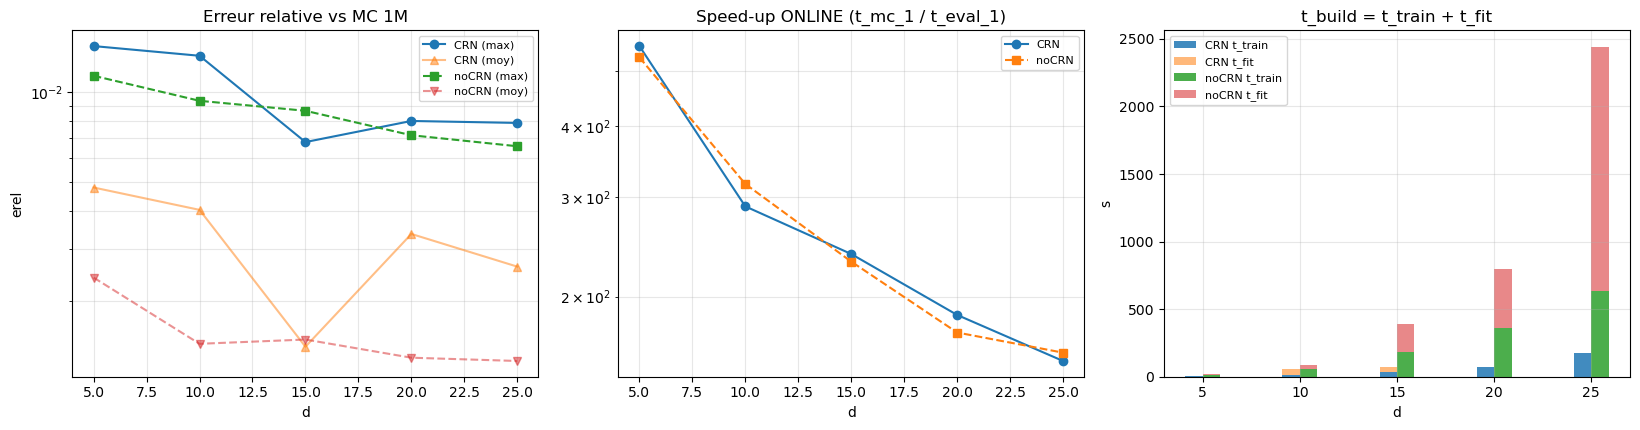

Speed-up TOTAL (build inclus, N = 100000 scenarios) :
regime    CRN  noCRN
d                   
5       449.0  328.0
10      173.0  152.0
15      160.0   62.0
20      142.0   40.0
25      103.0   19.0


In [11]:
dfB = pd.concat([g for g in (dfB_CRN.assign(regime="CRN"), dfB_noCRN.assign(regime="noCRN"))
                 if len(g)]) if (len(dfB_CRN) or len(dfB_noCRN)) else pd.DataFrame()

if len(dfB):
    fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.4))
    st = {"CRN": "-o", "noCRN": "--s"}
    for reg, g in dfB.groupby("regime"):
        g = g.sort_index()
        ax[0].semilogy(g.index, g.erel_max, st[reg], label="%s (max)" % reg)
        ax[0].semilogy(g.index, g.erel_mean, st[reg].replace("o", "^").replace("s", "v"),
                       alpha=.5, label="%s (moy)" % reg)
        ax[1].semilogy(g.index, g.spd_online, st[reg], label=reg)

    # t_build decompose : barres empilees t_train / t_fit, cote a cote CRN / noCRN
    width = 0.9
    for k, (reg, g) in enumerate(dfB.groupby("regime")):
        g = g.sort_index()
        x = np.asarray(g.index, float) + (k - 0.5) * width
        ax[2].bar(x, g.t_train, width=width, label="%s t_train" % reg, alpha=.85)
        ax[2].bar(x, g.t_fit, width=width, bottom=g.t_train, label="%s t_fit" % reg, alpha=.55)

    ax[0].set_title("Erreur relative vs MC 1M"); ax[0].set_xlabel("d"); ax[0].set_ylabel("erel")
    ax[1].set_title("Speed-up ONLINE (t_mc_1 / t_eval_1)"); ax[1].set_xlabel("d")
    ax[2].set_title("t_build = t_train + t_fit"); ax[2].set_xlabel("d"); ax[2].set_ylabel("s")
    for a in ax:
        a.grid(True, which="both", alpha=.3); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print("Speed-up TOTAL (build inclus, N = %d scenarios) :" % N_SCEN_SPEED)
    print(dfB.reset_index().pivot_table(index="d", columns="regime", values="spd_total").round(0))


### Lecture

- `spd_online` = combien de fois le proxy est plus rapide **par prix** que le MC 1M qu'il remplace ;
  `spd_total` amortit le build sur `N_SCEN_SPEED` scénarios. `tt_ranks` montre si le rang sature (`max_rank=7`) —
  s'il sature, l'erreur est probablement limitée par le rang, pas par le degré.
- La référence Exp B (MC 1M) porte son propre bruit ~ `sigma_payoff/sqrt(1M)` : les erreurs mesurées ne peuvent pas
  descendre en dessous.
